# Forecasting

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

In [2]:
OUTPUTS = PROJECT_ROOT / "outputs"
OUTPUTS.mkdir(parents=True, exist_ok=True)

In [3]:
from src.experiments.artifacts import ReconstructedStore

store = ReconstructedStore(OUTPUTS / "reconstructed")

In [4]:
import pandas as pd
import numpy as np

Repeat code from `imputation.ipynb`.

In [5]:
from src.data import load_ett, chronological_split, scale

train, test = chronological_split(load_ett())
train_s, test_s, scaler = scale(train=train, test=test)

Set horizon length.

In [6]:
H = 24 * 7

In [7]:
truth = test_s["OT"].iloc[:H].to_numpy()

### Baseline Forecast with Original Complete Data

**Exponential Smoothing**

In [8]:
from src.forecasters.exp_smoothing import ExpSmoothingForecaster

exp_base = ExpSmoothingForecaster(seasonal_periods=24, seasonal="add", trend="add", damped_trend=True)
exp_base.fit(train_s)
exp_base_forecast = exp_base.predict(horizon=H)

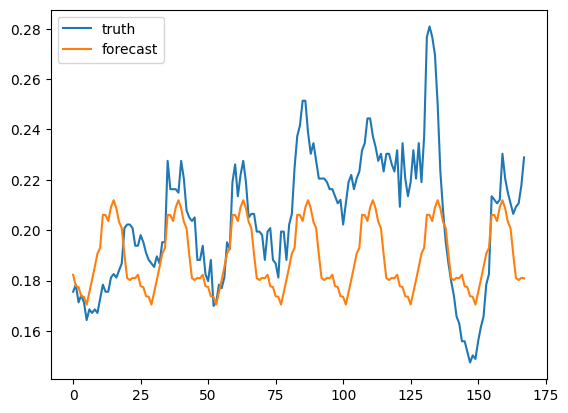

In [9]:
import matplotlib.pyplot as plt

plt.plot(truth, label="truth")
plt.plot(exp_base_forecast, label="forecast")
plt.legend()
plt.show()

In [10]:
np.sqrt(np.mean((exp_base_forecast - truth)**2))

np.float64(0.027124516363653085)

**XGBoost**

Baseline hyperparameter tuning, using MAE as metric to optimise (on training data).

Parameters

- Lag combinations from 1, 24, 48 and 168 (based on EDA).
- Learning rate.
- Number of trees.
- Max tree depth.

In [ ]:
import numpy as np
from sklearn.model_selection import ParameterGrid
from src.forecasters.xgb import XGBoostForecaster

val_h = H
train_fit = train_s.iloc[:-val_h]
val_truth = train_s["OT"].iloc[-val_h:].to_numpy()

param_grid = {
    "lags":          [[1, 24, 168], [24, 168], [1, 24, 48, 168]],
    "learning_rate": [0.03, 0.05, 0.1],
    "n_estimators":  [200, 400, 600],
    "max_depth":     [3, 4, 6],
}

results = []
for params in ParameterGrid(param_grid):
    f = XGBoostForecaster(random_state=0, **params)   # params already includes lags
    f.fit(train_fit)
    mae = np.mean(np.abs(f.predict(val_h) - val_truth))
    results.append((mae, params))

results.sort(key=lambda r: r[0])
print("\nBest:", results[0][1], "MAE", round(results[0][0], 5))

In [12]:
from src.forecasters.xgb import XGBoostForecaster

xgb_base = XGBoostForecaster(lags=[1, 24, 168],  learning_rate = 0.1, n_estimators = 600, max_depth=4)
xgb_base_trained = xgb_base.fit(train_s)
xgb_base_forecast = xgb_base_trained.predict(horizon=H)

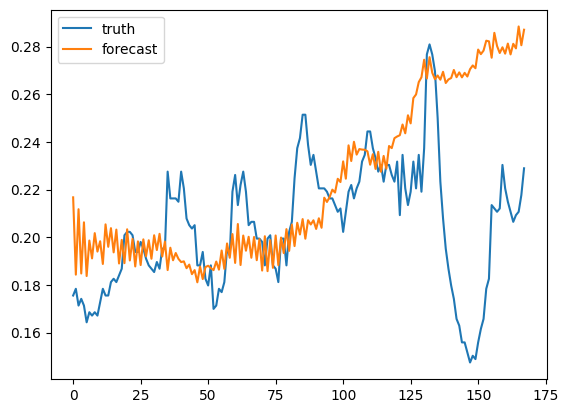

In [13]:
import matplotlib.pyplot as plt

plt.plot(truth, label="truth")
plt.plot(xgb_base_forecast, label="forecast")
plt.legend()
plt.show()

In [ ]:
np.sqrt(np.mean((xgb_base_forecast - truth) ** 2))

np.float64(0.04304256598685335)

### Forecasting Experiment

Extract OT scaler, and prepare unscaling function.

In [14]:
from src.forecasters.base import TARGET

ot_i = list(train.columns).index(TARGET)
ot_min, ot_max = scaler.data_min_[ot_i], scaler.data_max_[ot_i]

def unscale_ot(x):
    """Inverse-transform a scaled OT array/series back to raw units."""
    return x * (ot_max - ot_min) + ot_min

Unscale truth and baseline model outputs.

In [15]:
from src.experiments.forecasting import ForecastingExperiment
from src.forecasters import FORECASTERS

truth_raw = unscale_ot(truth)

baselines = {
    "exp_smoothing": unscale_ot(exp_base_forecast),
    "xgboost": unscale_ot(xgb_base_forecast),
}

Initiate experiment.

In [16]:
experiment = ForecastingExperiment(forecasters=list(FORECASTERS))
bv_df = experiment.run(horizon=H, store=store, truth=truth, baselines=baselines, unscale_fn = unscale_ot)

c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\statsmodels\tsa\base\t

Save bias-variance data output.

In [ ]:
# bv_df.to_parquet(OUTPUTS / "bias_variance.parquet")

In [22]:
bv_df[bv_df["imputer"] == "locf"]

,mechanism,proportion,imputer,forecaster,bias_vs_truth,bias_vs_baseline,variance
4,mar,10,locf,xgboost,55.084742,0.819155,10.307938
5,mar,10,locf,exp_smoothing,26.951998,0.005334,0.004571
12,mar,30,locf,xgboost,58.956848,1.328032,9.801049
13,mar,30,locf,exp_smoothing,28.278702,0.048247,0.031065
20,mar,50,locf,xgboost,54.069345,1.731102,7.215326
21,mar,50,locf,exp_smoothing,26.128744,0.076553,0.019063
28,mcar,10,locf,xgboost,53.186621,0.992586,9.138726
29,mcar,10,locf,exp_smoothing,27.251953,0.002498,0.004812
36,mcar,30,locf,xgboost,85.349248,6.038026,7.552531
37,mcar,30,locf,exp_smoothing,28.980228,0.072405,0.024216


<Axes: xlabel='proportion', ylabel='bias_vs_baseline'>

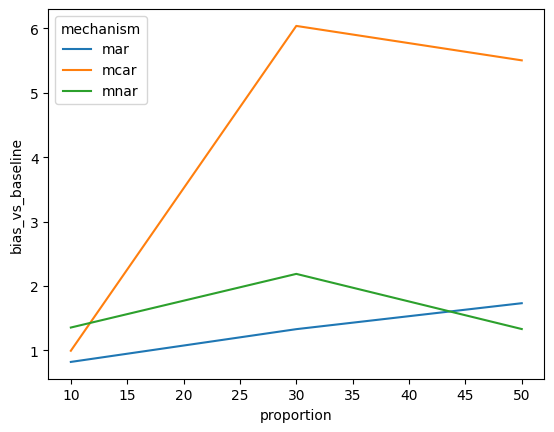

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

pltdf = bv_df[(bv_df["imputer"]=="locf") & (bv_df["forecaster"] == "xgboost")]

sns.lineplot(data=pltdf, x="proportion", y="bias_vs_baseline", hue="mechanism")

<Axes: xlabel='proportion', ylabel='bias_vs_baseline'>

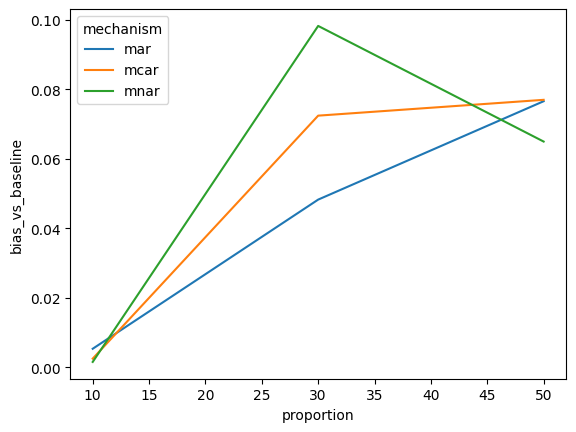

In [30]:
pltdf = bv_df[(bv_df["imputer"]=="locf") & (bv_df["forecaster"] == "exp_smoothing")]

sns.lineplot(data=pltdf, x="proportion", y="bias_vs_baseline", hue="mechanism")

<Axes: xlabel='proportion', ylabel='variance'>

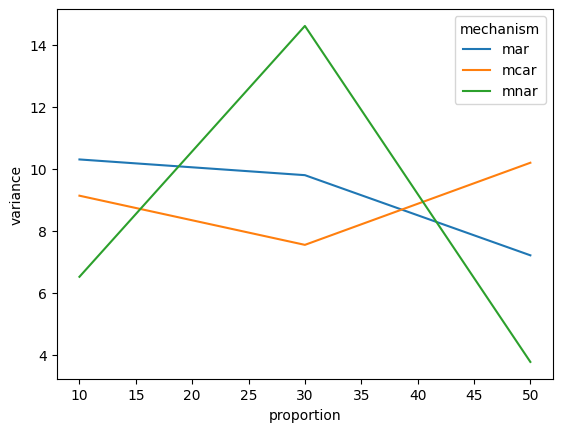

In [31]:
pltdf = bv_df[(bv_df["imputer"]=="locf") & (bv_df["forecaster"] == "xgboost")]

sns.lineplot(data=pltdf, x="proportion", y="variance", hue="mechanism")

<Axes: xlabel='proportion', ylabel='variance'>

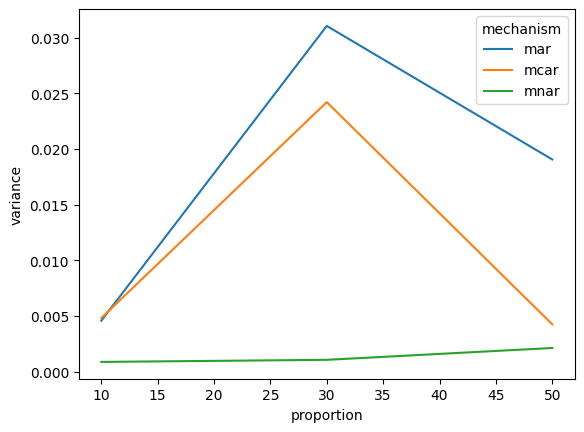

In [32]:
pltdf = bv_df[(bv_df["imputer"]=="locf") & (bv_df["forecaster"] == "exp_smoothing")]

sns.lineplot(data=pltdf, x="proportion", y="variance", hue="mechanism")